<a href="https://colab.research.google.com/github/BLTisandwich/OneData-MultiRep/blob/main/OneData_Omni_EE_OneEpisode_Colab_T4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OneData-Omni-EE · One Synchronized Robot Episode
### **RGB-D · 3D · Video · Robot State · End-Effector Actions · Force · Tactile Proxy · Impact Audio · Speech**

**Goal:** Generate **one complete, aligned** Franka Panda pick-and-place demonstration, inspect every modality on the same timeline, and export a ready-to-use training sample. This notebook is **data generation only**, not LoRA training.

**Execution:** Google Colab **CPU or T4** (PyBullet uses its CPU TinyRenderer here). No API key, external robot dataset, trained policy, or H200 required.

**Honest provenance:**
- **Measured in simulation:** robot joint states, forward-kinematics EE pose, object poses, PyBullet contacts, RGB, Depth, segmentation.
- **Scripted expert:** smoothly interpolated IK waypoints and gripper command. Object attachment is **kinematically assisted** to make a reliable *one-episode smoke test*; it is **not** an independently verified force-closure grasp.
- **Derived:** RGB-D point clouds, EE action labels, velocities.
- **Synthetic proxies:** contact-pad tactile heatmaps, impact/click sound; they are **not real tactile or acoustic measurements**.
- **Speech:** locally synthesized spoken goal, aligned at the **episode** level, not a time-resolved human/robot dialogue.

> **Success criteria:** (1) all arrays have identical frame/timestamp indexing, (2) the arm visibly transfers the cube, (3) end-effector action targets and next-step deltas are saved, (4) the synchronized dashboard and audio play, and (5) a complete ZIP exports.


## 1 · Install dependencies (Colab)

In [10]:
# 1. 快速使用 micromamba 安装已编译好的 pybullet 二进制包，避免 C++ 编译耗时
import os, sys

if not os.path.exists('/opt/pybullet_env'):
    !PY_VER=$(python3 -c "import sys; print(f'{sys.version_info.major}.{sys.version_info.minor}')") && \
     curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj bin/micromamba && \
     ./bin/micromamba create -y -q -p /opt/pybullet_env -c conda-forge "python=$PY_VER" pybullet && \
     rm -rf bin/micromamba

# 将 pybullet 环境路径加入到系统路径中，确保可直接 import
import sys, site
pybullet_path = f'/opt/pybullet_env/lib/python{sys.version_info.major}.{sys.version_info.minor}/site-packages'
if pybullet_path not in sys.path:
    sys.path.insert(0, pybullet_path)

# 安装其他纯 Python 依赖
!pip install -q gTTS imageio-ffmpeg trimesh

# 2. 完整验证所有依赖是否就绪
import shutil
try:
    import pybullet
    import numpy
    import imageio
    import cv2
    import matplotlib
    import scipy
    import trimesh
    import soundfile
    import plotly
    import PIL
    print('PyBullet dependencies ready. Offline TTS available:', bool(shutil.which('espeak-ng') or shutil.which('espeak')))
except ImportError as e:
    print('Dependency verification failed:', e)

PyBullet dependencies ready. Offline TTS available: True


## 2 · Configuration and shared timeline

In [11]:
# 确保把已编译好 pybullet 的 micromamba 路径注册进 sys.path
import sys
pybullet_path = f'/opt/pybullet_env/lib/python{sys.version_info.major}.{sys.version_info.minor}/site-packages'
if pybullet_path not in sys.path:
    sys.path.insert(0, pybullet_path)

import json, math, time, wave, os, subprocess, shutil
from pathlib import Path
import numpy as np
import pybullet as p
import pybullet_data
import imageio.v2 as imageio
import imageio_ffmpeg
from PIL import Image
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Video, Audio, HTML

ROOT = Path('/content/onedata_omni_ee' if Path('/content').exists() else './onedata_omni_ee')
OUT = ROOT / 'episode_0001'
OUT.mkdir(parents=True, exist_ok=True)
(OUT/'rgb').mkdir(exist_ok=True)
(OUT/'depth_mm').mkdir(exist_ok=True)
FPS = 12
PHYSICS_HZ = 240
STEPS_PER_FRAME = PHYSICS_HZ // FPS
DT = 1.0 / PHYSICS_HZ
DURATION_S = 8.0
W, H = 320, 240
NEAR, FAR = 0.04, 4.0
SEED = 21
np.random.seed(SEED)

# Defined in the same WORLD coordinates for the robot, object and target.
CUBE_START = np.array([0.54, -0.10, 0.027], dtype=np.float64)
GOAL_POS   = np.array([0.44,  0.20, 0.027], dtype=np.float64)
CUBE_EDGE = 0.054
INSTRUCTION = 'Pick up the blue cube and place it on the green target.'
print('Output directory:', OUT)
print('Total expected synchronized frames:', int(DURATION_S * FPS))

Output directory: /content/onedata_omni_ee/episode_0001
Total expected synchronized frames: 96


## 3 · Create a PyBullet scene and Panda arm
A single simulation state supplies **all** frames and annotations. There is no attempt to splice unrelated MOVi-C and robot episodes.

In [12]:
if p.isConnected(): p.disconnect()
CID = p.connect(p.DIRECT)
p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.setGravity(0, 0, -9.81)
p.setTimeStep(DT)
p.setPhysicsEngineParameter(numSolverIterations=80)
plane = p.loadURDF('plane.urdf', [0,0,-0.001])
p.changeVisualShape(plane, -1, rgbaColor=[0.70,0.73,0.78,1])

ROBOT = p.loadURDF('franka_panda/panda.urdf', [0,0,0], useFixedBase=True)
JOINTS = list(range(7)); FINGERS = [9,10]; EE_LINK=11
assert p.getNumJoints(ROBOT) >= 12, 'Unexpected Panda URDF joint indexing'

col_cube = p.createCollisionShape(p.GEOM_BOX, halfExtents=[CUBE_EDGE/2]*3)
vis_cube = p.createVisualShape(p.GEOM_BOX, halfExtents=[CUBE_EDGE/2]*3, rgbaColor=[0.10,0.40,0.98,1])
cube = p.createMultiBody(baseMass=0.09, baseCollisionShapeIndex=col_cube,
                         baseVisualShapeIndex=vis_cube, basePosition=CUBE_START.tolist())
p.changeDynamics(cube, -1, lateralFriction=1.4, restitution=0.06)

# Green goal disk is visible but does not collide with the cube.
vis_goal = p.createVisualShape(p.GEOM_CYLINDER, radius=0.055, length=0.004,
                               rgbaColor=[0.10,0.84,0.45,0.92])
goal = p.createMultiBody(baseMass=0, baseVisualShapeIndex=vis_goal,
                         basePosition=[float(GOAL_POS[0]),float(GOAL_POS[1]),0.002])

EE_QUAT = p.getQuaternionFromEuler([math.pi, 0.0, math.pi/4])  # downward pointing tool

camera_eye = [1.23, -1.10, 0.88]
camera_target = [0.36, 0.02, 0.19]
VIEW = p.computeViewMatrix(camera_eye, camera_target, cameraUpVector=[0,0,1])
PROJ = p.computeProjectionMatrixFOV(fov=52.0, aspect=W/H, nearVal=NEAR, farVal=FAR)
print('Panda robot body ID:', ROBOT, '| cube body ID:', cube, '| EE link ID:', EE_LINK)
print('Rendering backend: CPU TinyRenderer')

Panda robot body ID: 1 | cube body ID: 2 | EE link ID: 11
Rendering backend: CPU TinyRenderer


## 4 · Scripted IK demonstration
For this **first data-generation smoke test**, the arm follows smoothly interpolated kinematic waypoints. During the carry phase a scripted EE-to-object attachment is used to make the transfer reproducible. That flag is saved in the dataset so it can never be confused with genuine autonomous grasping.

In [13]:
# Each waypoint = [time, world-frame target EE xyz, finger joint opening (m), phase].
WAYPOINTS = [
 (0.0, [0.48,-0.10,0.31], 0.040, 'approach'),
 (1.1, [0.54,-0.10,0.22], 0.040, 'approach'),
 (2.1, [0.54,-0.10,0.090],0.040, 'descend'),
 (2.65,[0.54,-0.10,0.090],0.000, 'grasp'),
 (3.05,[0.54,-0.10,0.090],0.000, 'grasp_hold'),
 (4.05,[0.54,-0.10,0.28], 0.000, 'lift'),
 (5.35,[0.44, 0.20,0.28], 0.000, 'transfer'),
 (6.40,[0.44, 0.20,0.090],0.000, 'lower'),
 (6.92,[0.44, 0.20,0.090],0.040, 'release'),
 (7.78,[0.44, 0.20,0.29], 0.040, 'retract'),
 (8.00,[0.44, 0.20,0.29], 0.040, 'done')
]
LOWER = [p.getJointInfo(ROBOT,j)[8] for j in JOINTS]
UPPER = [p.getJointInfo(ROBOT,j)[9] for j in JOINTS]
RANGES = [u-l for l,u in zip(LOWER,UPPER)]
REST = [0.0,-0.35,0.0,-2.20,0.0,1.90,0.79]
qs=[]
for ts, xyz, finger, phase in WAYPOINTS:
    ik = p.calculateInverseKinematics(
        ROBOT, EE_LINK, targetPosition=xyz, targetOrientation=EE_QUAT,
        lowerLimits=LOWER, upperLimits=UPPER, jointRanges=RANGES,
        restPoses=REST, maxNumIterations=180, residualThreshold=1e-5)
    qs.append(np.array(ik[:7], dtype=np.float64))
qs=np.asarray(qs)
t_way=np.array([x[0] for x in WAYPOINTS])
xyz_way=np.array([x[1] for x in WAYPOINTS])
finger_way=np.array([x[2] for x in WAYPOINTS])

# The IK pose should be reachable, otherwise fail before exporting misleading data.
ik_errors=[]
for (_, xyz, _, _), q in zip(WAYPOINTS, qs):
    for i,j in enumerate(JOINTS): p.resetJointState(ROBOT, j, float(q[i]))
    actual=np.array(p.getLinkState(ROBOT,EE_LINK, computeForwardKinematics=True)[4])
    ik_errors.append(float(np.linalg.norm(actual - xyz)))
print('Waypoint IK position errors [m]:', np.round(ik_errors,3).tolist())
print('Maximum IK position error:', round(max(ik_errors),4),'m')
if max(ik_errors)>0.15:
    print('WARNING: One waypoint is difficult to reach. Output will be saved but inspect the EE error plot.')

def sample_plan(t):
    k=int(np.clip(np.searchsorted(t_way,t,side='right')-1,0,len(t_way)-2))
    alpha=float(np.clip((t-t_way[k])/(t_way[k+1]-t_way[k]),0,1))
    alpha=alpha*alpha*(3-2*alpha)  # smoothstep
    q=(1-alpha)*qs[k]+alpha*qs[k+1]
    xyz=(1-alpha)*xyz_way[k]+alpha*xyz_way[k+1]
    grip=float((1-alpha)*finger_way[k]+alpha*finger_way[k+1])
    return q,xyz,grip,WAYPOINTS[k+1][3]

# Start the arm from first waypoint, fingers open.
for j,q in zip(JOINTS,qs[0]): p.resetJointState(ROBOT,j,float(q))
for j in FINGERS: p.resetJointState(ROBOT,j,0.04)
p.performCollisionDetection()
print('Ready to generate one 8-second expert episode.')

Waypoint IK position errors [m]: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Maximum IK position error: 0.0 m
Ready to generate one 8-second expert episode.


## 5 · Roll out physics + capture synchronized multi-sensor frames
**One physics step clock** drives RGB-D, segmentation, EE pose, robot state, object pose, contacts, pressure proxy, and the action target. We record at 12 FPS.

In [14]:
logs=[]; rgbs=[]; depths=[]; segmentations=[]; tactile_frames=[]
GRASP_T=2.83
RELEASE_T=6.73
held=False
attachment_pos=None; attachment_quat=None
start=time.time()

# Contact-pad heatmaps: deliberately synthetic force proxies, NOT DIGIT measurements.
YY,XX=np.mgrid[0:16,0:16]
left_pad = np.exp(-((XX-5.5)**2+(YY-8)**2)/(2*2.0**2))
right_pad= np.exp(-((XX-10.0)**2+(YY-8)**2)/(2*2.0**2))

for step in range(int(round(DURATION_S*PHYSICS_HZ))):
    t=(step+1)*DT
    q_target, xyz_target, finger_target, phase = sample_plan(t)
    # Explicit kinematic teacher for guaranteed repeatability, not dynamic PD control.
    for j, qval in zip(JOINTS, q_target): p.resetJointState(ROBOT,j,float(qval))
    for j in FINGERS: p.resetJointState(ROBOT,j,float(np.clip(finger_target,0.0,0.04)))

    ee_state=p.getLinkState(ROBOT, EE_LINK, computeForwardKinematics=True)
    ee_wpos, ee_wquat = ee_state[4], ee_state[5]
    if t>=GRASP_T and not held and t<RELEASE_T:
        inv_p, inv_q=p.invertTransform(ee_wpos,ee_wquat)
        cp,cq=p.getBasePositionAndOrientation(cube)
        attachment_pos, attachment_quat=p.multiplyTransforms(inv_p,inv_q,cp,cq)
        held=True
    if held:
        cp,cq=p.multiplyTransforms(ee_wpos,ee_wquat,attachment_pos,attachment_quat)
        p.resetBasePositionAndOrientation(cube,cp,cq)
        p.resetBaseVelocity(cube,[0,0,0],[0,0,0])
    if t>=RELEASE_T and held:
        held=False
    p.stepSimulation()
    if held:
        # End-of-step correction makes this scripted attachment deterministic.
        cur=p.getLinkState(ROBOT,EE_LINK,computeForwardKinematics=True)
        cp,cq=p.multiplyTransforms(cur[4],cur[5],attachment_pos,attachment_quat)
        p.resetBasePositionAndOrientation(cube,cp,cq)
        p.resetBaseVelocity(cube,[0,0,0],[0,0,0])

    if (step+1)%STEPS_PER_FRAME!=0: continue

    ee_state=p.getLinkState(ROBOT,EE_LINK,computeForwardKinematics=True)
    cube_pos,cube_quat=p.getBasePositionAndOrientation(cube)
    joints=np.array([p.getJointState(ROBOT,j)[0] for j in JOINTS], dtype=np.float32)
    fingers=np.array([p.getJointState(ROBOT,j)[0] for j in FINGERS], dtype=np.float32)
    # PyBullet simulated normal contact force; does NOT include scripted attachment force.
    contact_robot_cube=float(sum(c[9] for c in p.getContactPoints(bodyA=ROBOT, bodyB=cube)))
    contact_floor_cube=float(sum(c[9] for c in p.getContactPoints(bodyA=cube, bodyB=plane)))
    grip_proxy_N=5.0 if held else (1.0 if (phase=='grasp' and finger_target<0.01) else 0.0)
    pressure=np.stack([left_pad*grip_proxy_N, right_pad*grip_proxy_N],axis=0).astype(np.float32)

    img=p.getCameraImage(W,H,VIEW,PROJ,renderer=p.ER_TINY_RENDERER,
                         flags=p.ER_SEGMENTATION_MASK_OBJECT_AND_LINKINDEX)
    rgba=np.asarray(img[2],dtype=np.uint8).reshape(H,W,4)
    rgb=rgba[:,:,:3].copy()
    zbuffer=np.asarray(img[3],dtype=np.float32).reshape(H,W)
    depth=(FAR*NEAR)/(FAR-(FAR-NEAR)*zbuffer)
    seg=np.asarray(img[4],dtype=np.int32).reshape(H,W)
    logs.append(dict(t=float(t),phase=phase,
        joint_pos=joints, finger_joint_pos=fingers,
        ee_pos=np.array(ee_state[4],dtype=np.float32),ee_quat=np.array(ee_state[5],dtype=np.float32),
        target_ee_pos=np.asarray(xyz_target,dtype=np.float32),target_ee_quat=np.asarray(EE_QUAT,dtype=np.float32),
        gripper_command=float(finger_target),cube_pos=np.asarray(cube_pos,dtype=np.float32),
        cube_quat=np.asarray(cube_quat,dtype=np.float32),
        robot_cube_contact_N=contact_robot_cube,cube_floor_contact_N=contact_floor_cube,
        grip_force_proxy_N=grip_proxy_N,kinematic_attachment=bool(held)))
    rgbs.append(rgb); depths.append(depth.astype(np.float32))
    segmentations.append(seg); tactile_frames.append(pressure)

rgb=np.stack(rgbs)
depth=np.stack(depths)
segmentation=np.stack(segmentations)
tactile=np.stack(tactile_frames)
T=len(logs)
times=np.asarray([x['t'] for x in logs],dtype=np.float32)
EE=np.stack([x['ee_pos'] for x in logs])
CUBE=np.stack([x['cube_pos'] for x in logs])
print(f'Generated {T} frames at {FPS} Hz in {time.time()-start:.1f}s')
print('EE motion [m]:', np.round(EE[-1]-EE[0],3))
print('Object move from original position [m]:',round(float(np.linalg.norm(CUBE[-1]-CUBE_START)),3))
print('Grasp attachment frames:',sum(x['kinematic_attachment'] for x in logs))
assert T==int(DURATION_S*FPS), 'Frame count mismatch'
assert sum(x['kinematic_attachment'] for x in logs)>5, 'No kinematic grasp phase was captured'
assert np.linalg.norm(CUBE[-1]-CUBE_START)>0.1, 'Cube did not move: inspect the robot trajectory'
print('Synthetic trajectory smoke test PASS.')

Generated 96 frames at 12 Hz in 19.2s
EE motion [m]: [-0.041  0.3   -0.019]
Object move from original position [m]: 0.316
Grasp attachment frames: 47
Synthetic trajectory smoke test PASS.


## 6 · Construct EE labels and export time series
Frame **t** has observation `o_t` and an action label `a_t = EE(t+1) - EE(t)` plus next gripper command, with a separate **valid mask** for the last frame. Commanded target pose is also saved. All 3D vectors are in **meters and world coordinates**.

In [15]:
def stackkey(k):return np.stack([x[k] for x in logs])
JOINT_Q=stackkey('joint_pos')
EE_QUAT_ACT=stackkey('ee_quat')
EE_TARGET=stackkey('target_ee_pos')
EE_TARGET_Q=stackkey('target_ee_quat')
GRIP=stackkey('finger_joint_pos')
GRIP_CMD=np.array([x['gripper_command'] for x in logs],dtype=np.float32)
CUBE_Q=stackkey('cube_quat')
HELD=np.array([x['kinematic_attachment'] for x in logs],dtype=np.bool_)
ROBOT_CONTACT=np.array([x['robot_cube_contact_N'] for x in logs],dtype=np.float32)
FLOOR_CONTACT=np.array([x['cube_floor_contact_N'] for x in logs],dtype=np.float32)
GRASP_PROXY=np.array([x['grip_force_proxy_N'] for x in logs],dtype=np.float32)
PHASE=np.array([x['phase'] for x in logs],dtype='U20')

JOINT_DQ=np.gradient(JOINT_Q,1/FPS,axis=0)
CUBE_V=np.gradient(CUBE,1/FPS,axis=0)
EE_V=np.gradient(EE,1/FPS,axis=0)
ACTION_NEXT_DELTA=np.zeros_like(EE)
ACTION_NEXT_DELTA[:-1]=EE[1:]-EE[:-1]
ACTION_GRIP_NEXT=GRIP_CMD.copy()
ACTION_GRIP_NEXT[:-1]=GRIP_CMD[1:]
VALID_ACTION=np.ones(T,dtype=np.bool_); VALID_ACTION[-1]=False

np.savez_compressed(OUT/'ee_robot_actions.npz',
    timestamp_s=times,sim_step=np.arange(1,T+1)*STEPS_PER_FRAME,
    joint_position_rad=JOINT_Q,joint_velocity_rad_s=JOINT_DQ,
    gripper_joint_position_m=GRIP,gripper_command_m=GRIP_CMD,
    ee_position_world_m=EE,ee_quaternion_world_xyzw=EE_QUAT_ACT,
    ee_velocity_world_m_s=EE_V,ee_target_position_world_m=EE_TARGET,
    ee_target_quaternion_world_xyzw=EE_TARGET_Q,
    action_next_ee_delta_world_m=ACTION_NEXT_DELTA,
    action_next_gripper_command_m=ACTION_GRIP_NEXT,action_valid=VALID_ACTION,
    cube_position_world_m=CUBE,cube_quaternion_world_xyzw=CUBE_Q,
    cube_velocity_world_m_s=CUBE_V,
    robot_cube_contact_normal_force_N=ROBOT_CONTACT,
    cube_floor_contact_normal_force_N=FLOOR_CONTACT,
    grip_force_PROXY_N=GRASP_PROXY,
    kinematic_grasp_attachment=HELD,phase=PHASE)
np.savez_compressed(OUT/'tactile_PROXY.npz',timestamp_s=times,
                    pressure_pad_left_right_PROXY=tactile)
print('Saved aligned EE, robot, object, contact, gripper and tactile arrays.')
print('Input:',EE.shape, 'Action:',ACTION_NEXT_DELTA.shape, 'Tactile:',tactile.shape)

Saved aligned EE, robot, object, contact, gripper and tactile arrays.
Input: (96, 3) Action: (96, 3) Tactile: (96, 2, 16, 16)


## 7 · Export RGB, Depth, Segmentation and world-frame 3D Point Clouds
RGB-D point clouds are from the **same camera frame**. Object segmentation is obtained from PyBullet body IDs (not guessed from pixel colors). A static cube OBJ mesh is also provided.

In [16]:
# In PyBullet segmentation -1 denotes background. The lower 24 bits encode body ID.
BODY_ID=np.where(segmentation<0,-1,segmentation & ((1<<24)-1))

# OpenGL inverse projection: pixel coordinates and depth buffer -> WORLD frame.
PV=np.asarray(PROJ,dtype=np.float64).reshape(4,4,order='F') @ np.asarray(VIEW,dtype=np.float64).reshape(4,4,order='F')
INV_PV=np.linalg.inv(PV)
xx,yy=np.meshgrid(np.arange(W),np.arange(H))
X=2.0*(xx+0.5)/W-1.0
Y=1.0-2.0*(yy+0.5)/H

def unproject_pixels(depth_map,pixel_rows,pixel_cols):
    zbuf=(FAR - (FAR*NEAR)/np.maximum(depth_map[pixel_rows,pixel_cols],1e-6))/(FAR-NEAR)
    clip=np.stack([X[pixel_rows,pixel_cols],Y[pixel_rows,pixel_cols],
                   2.0*zbuf-1,np.ones(len(pixel_rows))],axis=-1)
    world=clip@INV_PV.T
    return (world[:,:3]/world[:,3:4]).astype(np.float32)

rng=np.random.default_rng(SEED)
SCENE_PCS=[]; CUBE_PCS=[]; CUBE_PCS_VALID=[]
for k in range(T):
    Image.fromarray(rgb[k]).save(OUT/'rgb'/f'{k:04d}.png')
    dmm=np.where((depth[k]>NEAR)&(depth[k]<FAR-0.02),depth[k]*1000.0,0)
    Image.fromarray(np.clip(dmm,0,65535).astype(np.uint16)).save(OUT/'depth_mm'/f'{k:04d}.png')
    # Scene samples from valid foreground; cube samples come ONLY from cube pixels.
    fg=(BODY_ID[k]>=0)&(depth[k]<FAR-0.02)
    cy,cx=np.where(fg)
    if len(cx)==0: raise RuntimeError(f'No foreground rendered in frame {k}')
    ind=rng.choice(len(cx),size=512,replace=len(cx)<512)
    SCENE_PCS.append(unproject_pixels(depth[k],cy[ind],cx[ind]))
    by,bx=np.where(BODY_ID[k]==cube)
    valid=(len(bx)>0)
    CUBE_PCS_VALID.append(valid)
    if valid:
        ind=rng.choice(len(bx),size=256,replace=len(bx)<256)
        CUBE_PCS.append(unproject_pixels(depth[k],by[ind],bx[ind]))
    else:
        CUBE_PCS.append(np.full((256,3),np.nan,dtype=np.float32))
SCENE_PCS=np.stack(SCENE_PCS)
CUBE_PCS=np.stack(CUBE_PCS)
CUBE_PCS_VALID=np.array(CUBE_PCS_VALID,dtype=np.bool_)
np.savez_compressed(OUT/'rgbd_segmentation.npz',timestamp_s=times,
                    depth_world_m=depth.astype(np.float16),
                    segmentation_raw_int32=segmentation,
                    segmentation_body_id=BODY_ID.astype(np.int16))
np.savez_compressed(OUT/'pointcloud_world.npz',timestamp_s=times,
    scene_xyz_world_m=SCENE_PCS,cube_xyz_world_m=CUBE_PCS,cube_visible=CUBE_PCS_VALID)

# Mesh in the cube's *local frame*, transformed by cube pose from ee_robot_actions.npz.
import trimesh
trimesh.creation.box(extents=[CUBE_EDGE]*3).export(OUT/'cube_mesh_local.obj')

with imageio.get_writer(str(OUT/'rgb_video.mp4'),fps=FPS,codec='libx264',quality=7,macro_block_size=16) as writer:
    for fr in rgb: writer.append_data(fr)
print('Generated:',OUT/'rgb_video.mp4')
print('Cube visible frames:',int(CUBE_PCS_VALID.sum()),'/',T)
print('Scene PC shape:',SCENE_PCS.shape,'Cube-only PC shape:',CUBE_PCS.shape)

Generated: /content/onedata_omni_ee/episode_0001/rgb_video.mp4
Cube visible frames: 96 / 96
Scene PC shape: (96, 512, 3) Cube-only PC shape: (96, 256, 3)


## 8 · Event-locked synthetic impact audio + real spoken instruction WAV
The sound effects are **procedural audio cues** placed at simulated grasp/release event timestamps; they are not calibrated physical acoustics. Speech is synthesized separately, so the WAV actually contains spoken words (not a beep).

In [17]:
from scipy.io import wavfile
SR=16000

def add_sound(x,t0,freq,amp=.23,length=.24):
    start=int(t0*SR)
    duration=min(int(length*SR),len(x)-start)
    if duration<=0:return
    tt=np.arange(duration,dtype=np.float64)/SR
    rng_sound=np.random.default_rng(int(t0*1000)+10)
    wave=(np.sin(2*np.pi*freq*tt)+0.28*np.sin(2*np.pi*freq*2.1*tt)+
          0.16*rng_sound.standard_normal(duration))*np.exp(-22*tt)
    x[start:start+duration]+=amp*wave

sfx=np.zeros(int(DURATION_S*SR),dtype=np.float64)
add_sound(sfx,GRASP_T,880,0.12,0.15)  # gripper close cue
add_sound(sfx,RELEASE_T,390,0.25,0.36) # placement/release cue
sfx=np.clip(sfx,-0.95,0.95)
wavfile.write(OUT/'event_sfx_SYNTHETIC.wav',SR,(sfx*32767).astype(np.int16))

voice_cmd=shutil.which('espeak-ng') or shutil.which('espeak')
speech_path=OUT/'spoken_instruction.wav'
if voice_cmd:
    cp=subprocess.run([voice_cmd,'-s','137','-w',str(speech_path),INSTRUCTION],
                      capture_output=True,text=True)
    if cp.returncode!=0 or not speech_path.exists() or speech_path.stat().st_size<500:
        raise RuntimeError('Offline TTS failed: '+cp.stderr[-500:])
else:
    # Fallback only if offline TTS is missing; requires Colab internet.
    try:
        from gtts import gTTS
        gTTS(INSTRUCTION,lang='en').save(str(OUT/'spoken_instruction.mp3'))
        ff=imageio_ffmpeg.get_ffmpeg_exe()
        subprocess.run([ff,'-y','-loglevel','error','-i',str(OUT/'spoken_instruction.mp3'),'-ar','16000','-ac','1',str(speech_path)],check=True)
    except Exception as ex:
        raise RuntimeError('Speech WAV not generated. Install espeak-ng via apt-get; do not substitute a synthetic beep.') from ex

srate,spoken=wavfile.read(speech_path)
speech_duration=len(spoken)/srate
print('Event SFX:',len(sfx)/SR,'seconds (aligned to physics time)')
print('Spoken instruction:',repr(INSTRUCTION))
print('Speech WAV duration:',round(speech_duration,2),'s; sample rate:',srate)
display(Audio(filename=str(speech_path)))
display(Audio(filename=str(OUT/'event_sfx_SYNTHETIC.wav')))

Event SFX: 8.0 seconds (aligned to physics time)
Spoken instruction: 'Pick up the blue cube and place it on the green target.'
Speech WAV duration: 4.06 s; sample rate: 22050


## 9 · Dataset manifest, reproducibility notes, and explicit training boundary
Never feed `action_next_*` or any future observation as an input when training an action model. Split by **episode**, not by adjacent frames, once multiple episodes are collected.

In [18]:
manifest={
  'dataset':'OneData-Omni-EE-Synthetic-v0', 'episode_id':'episode_0001',
  'source':'PyBullet DIRECT + CPU TinyRenderer + scripted kinematic Panda teacher',
  'robot':'Franka Panda (pybullet_data/franka_panda/panda.urdf)',
  'fps':FPS,'physics_hz':PHYSICS_HZ,'duration_seconds':DURATION_S,'num_frames':T,
  'coordinate_frame':'world', 'position_unit':'m', 'rotation':'quaternion_xyzw',
  'force_unit':'N', 'tactile_unit':'unnormalized_synthetic_proxy',
  'object_ids':{'robot':int(ROBOT),'cube':int(cube),'goal':int(goal),'ground':int(plane)},
  'object_geometry':{'cube_mesh_local':'cube_mesh_local.obj','cube_edge_m':CUBE_EDGE},
  'language_instruction':INSTRUCTION,
  'speech':{'file':'spoken_instruction.wav','role':'episode_level_goal',
            'starts_at_episode_second':0.0,'duration_s':float(speech_duration)},
  'event_cues':[{'name':'grasp','time_s':GRASP_T,'source':'scripted'},
                {'name':'release','time_s':RELEASE_T,'source':'scripted'}],
  'modalities':{
      'rgb_video':'rgb_video.mp4; rgb/ ordered frames',
      'depth_seg':'rgbd_segmentation.npz; depth_mm/ png',
      'point_cloud':'pointcloud_world.npz (world XYZ)',
      'mesh':'cube_mesh_local.obj + cube 6DoF pose from ee_robot_actions.npz',
      'robot_proprio_ee_actions':'ee_robot_actions.npz',
      'tactile_proxy':'tactile_PROXY.npz',
      'event_audio':'event_sfx_SYNTHETIC.wav',
      'speech':'spoken_instruction.wav'},
  'limitations':[
      'Kinematic scripted IK trajectories; not learned or torque-level controls',
      'A grasp attachment is explicitly imposed between GRASP_T and RELEASE_T, not force closure',
      'Tactile heatmap is heuristic contact-pad proxy, not a real sensor or physics-validated pressure field',
      'Audio events are synthesized from scripted timestamps, not measured collision acoustics',
      'Speech is aligned at episode level and does not provide per-frame speaker timestamps',
      'No demonstration of unseen-scene generalization from a single episode',
      'Last frame has no next-action target and must be masked',
      'Camera/depth data and pointcloud are synchronized at each recorded timestamp'
  ]
}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
(OUT/'task_instruction.txt').write_text(INSTRUCTION+'\n',encoding='utf-8')
print(json.dumps({k:manifest[k] for k in ['dataset','episode_id','num_frames','coordinate_frame','modalities']},indent=2))

{
  "dataset": "OneData-Omni-EE-Synthetic-v0",
  "episode_id": "episode_0001",
  "num_frames": 96,
  "coordinate_frame": "world",
  "modalities": {
    "rgb_video": "rgb_video.mp4; rgb/ ordered frames",
    "depth_seg": "rgbd_segmentation.npz; depth_mm/ png",
    "point_cloud": "pointcloud_world.npz (world XYZ)",
    "mesh": "cube_mesh_local.obj + cube 6DoF pose from ee_robot_actions.npz",
    "robot_proprio_ee_actions": "ee_robot_actions.npz",
    "tactile_proxy": "tactile_PROXY.npz",
    "event_audio": "event_sfx_SYNTHETIC.wav",
    "speech": "spoken_instruction.wav"
  }
}


## 10 · Automatic alignment + action-label integrity checks
If an invariant fails, stop and inspect instead of exporting mismatched modalities.

In [19]:
checks={}
checks['timestamps strictly increasing']=bool(np.all(np.diff(times)>0))
checks['exact 12 FPS']=bool(np.allclose(np.diff(times),1/FPS,atol=1e-5))
checks['all modalities match T']=all(arr.shape[0]==T for arr in [rgb,depth,segmentation,EE,JOINT_Q,CUBE,tactile,SCENE_PCS,CUBE_PCS])
checks['all state arrays finite']=bool(all(np.isfinite(x).all() for x in [EE,EE_TARGET,JOINT_Q,CUBE,ACTION_NEXT_DELTA]))
checks['next EE delta correct']=bool(np.allclose(ACTION_NEXT_DELTA[:-1],EE[1:]-EE[:-1],atol=1e-6))
checks['action mask excludes last']=bool(VALID_ACTION[:-1].all() and not VALID_ACTION[-1])
checks['grasp phase is annotated']=bool(HELD.any())
checks['object moved across scene']=bool(np.linalg.norm(CUBE[-1]-CUBE_START)>0.10)
checks['cube visible in some frames']=bool(CUBE_PCS_VALID.any())
checks['tactile active only during grip proxy']=bool((tactile.max((1,2,3))>1e-3).sum()>0)
checks['speech wav created']=bool(speech_path.is_file() and speech_path.stat().st_size>500)
checks['event audio created']=bool((OUT/'event_sfx_SYNTHETIC.wav').exists() and np.max(np.abs(sfx))>0)
checks['RGB video created']=bool((OUT/'rgb_video.mp4').stat().st_size>500)
print('ONE-EPISODE DATASET AUDIT')
for name,ok in checks.items():print(('PASS' if ok else 'FAIL').ljust(7), name)
assert all(checks.values()),'Data validation failed. Please inspect the failed check.'
print(f'\nALL {len(checks)} CHECKS PASSED. EE/gripper labels and sensory observations share the same timeline.')

ONE-EPISODE DATASET AUDIT
PASS    timestamps strictly increasing
PASS    exact 12 FPS
PASS    all modalities match T
PASS    all state arrays finite
PASS    next EE delta correct
PASS    action mask excludes last
PASS    grasp phase is annotated
PASS    object moved across scene
PASS    cube visible in some frames
PASS    tactile active only during grip proxy
PASS    speech wav created
PASS    event audio created
PASS    RGB video created

ALL 13 CHECKS PASSED. EE/gripper labels and sensory observations share the same timeline.


## 11 · Quick diagnostic: EE target, actual EE, object trajectory and tactile

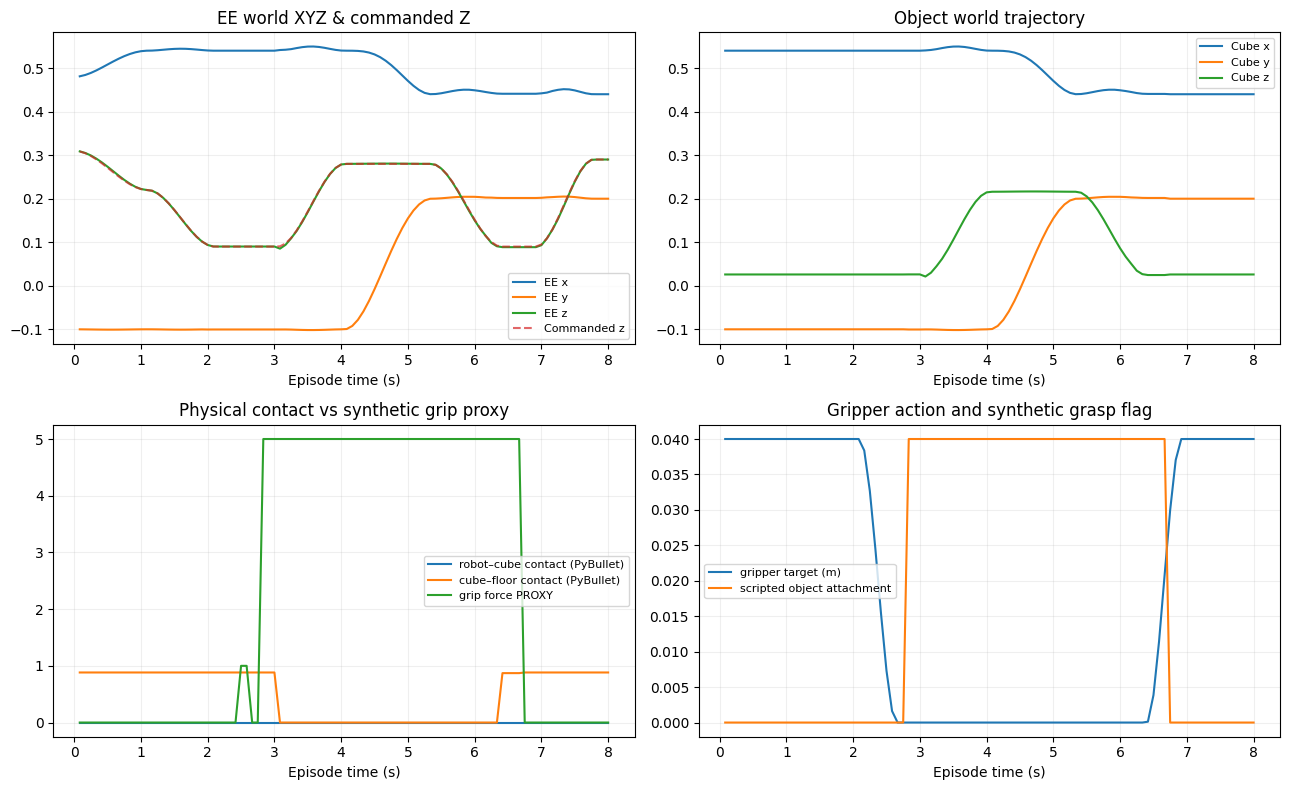

Scene start vs end images:


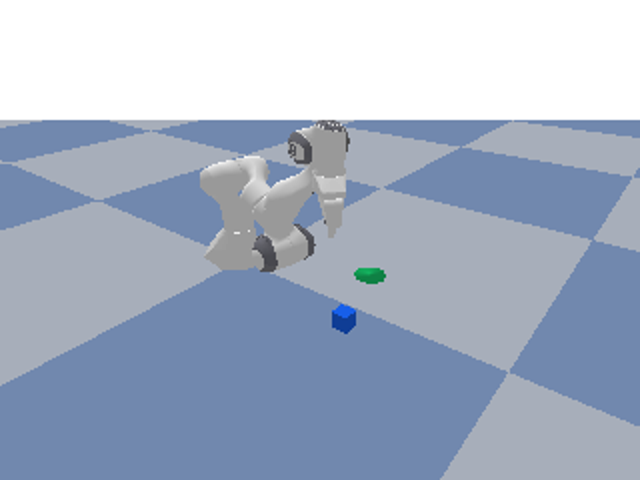

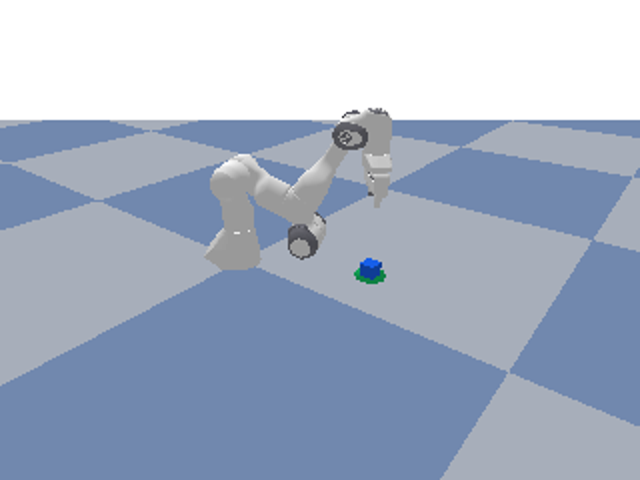

In [20]:
fig,axs=plt.subplots(2,2,figsize=(13,8))
axs[0,0].plot(times,EE[:,0],label='EE x'); axs[0,0].plot(times,EE[:,1],label='EE y'); axs[0,0].plot(times,EE[:,2],label='EE z')
axs[0,0].plot(times,EE_TARGET[:,2],'--',alpha=.7,label='Commanded z'); axs[0,0].set_title('EE world XYZ & commanded Z');axs[0,0].legend(fontsize=8)
axs[0,1].plot(times,CUBE[:,0],label='Cube x');axs[0,1].plot(times,CUBE[:,1],label='Cube y');axs[0,1].plot(times,CUBE[:,2],label='Cube z');axs[0,1].set_title('Object world trajectory');axs[0,1].legend(fontsize=8)
axs[1,0].plot(times,ROBOT_CONTACT,label='robot–cube contact (PyBullet)');axs[1,0].plot(times,FLOOR_CONTACT,label='cube–floor contact (PyBullet)');axs[1,0].plot(times,GRASP_PROXY,label='grip force PROXY');axs[1,0].set_title('Physical contact vs synthetic grip proxy');axs[1,0].legend(fontsize=8)
axs[1,1].plot(times,GRIP_CMD,label='gripper target (m)');axs[1,1].plot(times,HELD.astype(float)*0.04,label='scripted object attachment');axs[1,1].set_title('Gripper action and synthetic grasp flag');axs[1,1].legend(fontsize=8)
for ax in axs.flat:ax.set_xlabel('Episode time (s)');ax.grid(alpha=.2)
plt.tight_layout(); plt.savefig(OUT/'diagnostics.png',dpi=140);plt.show()
print('Scene start vs end images:')
display(Image.fromarray(rgb[0]).resize((640,480)))
display(Image.fromarray(rgb[-1]).resize((640,480)))

## 12 · Generate the synchronized 4-panel cinematic dashboard
**Top-left:** Panda / scene RGB. **Top-right:** depth + cube segmentation. **Bottom-left:** EE and cube trajectory in top-down view. **Bottom-right:** tactile heatmap and real/proxy force histories. All panels advance with the same `timestamp_s`.

In [21]:
DW,DH=960,608

def panel_text(im,text,x,y,size=.60,color=(245,245,245),weight=1):
    cv2.putText(im,str(text),(int(x),int(y)),cv2.FONT_HERSHEY_SIMPLEX,size,(0,0,0),weight+3,cv2.LINE_AA)
    cv2.putText(im,str(text),(int(x),int(y)),cv2.FONT_HERSHEY_SIMPLEX,size,color,weight,cv2.LINE_AA)


def make_dashboard_frame(k):
    im=np.zeros((DH,DW,3),dtype=np.uint8)
    im[:]=(19,25,33)
    # RGB panel 480x290
    photo=cv2.resize(cv2.cvtColor(rgb[k],cv2.COLOR_RGB2BGR),(470,275))
    im[47:322,5:475]=photo
    panel_text(im,'OMNI-EE  /  ROBOT RGB',14,30,.62,(115,220,255),2)
    panel_text(im,f't={times[k]:.2f}s   phase={PHASE[k]}',18,303,.48)
    # Depth | segmentation, each 235x135
    d=depth[k]; d_color=cv2.applyColorMap(np.clip((1-np.clip(d/2.2,0,1))*255,0,255).astype(np.uint8),cv2.COLORMAP_TURBO)
    mask=(BODY_ID[k]==cube).astype(np.uint8)
    seg_color=cv2.cvtColor(rgb[k],cv2.COLOR_RGB2BGR).copy()
    seg_color[mask>0]=0.45*seg_color[mask>0]+0.55*np.array([255,50,230])
    im[58:194,490:725]=cv2.resize(d_color,(235,136))
    im[58:194,735:959]=cv2.resize(seg_color,(224,136))
    panel_text(im,'DEPTH',500,45,.56,(115,220,255))
    panel_text(im,'CUBE MASK',744,45,.56,(115,220,255))
    # Two snapshots of labeled 3D vectors in text
    panel_text(im,'EE xyz   '+' '.join(f'{v:+.2f}' for v in EE[k]),500,226,.52)
    panel_text(im,'Target   '+' '.join(f'{v:+.2f}' for v in EE_TARGET[k]),500,249,.52)
    panel_text(im,'Cube xyz '+' '.join(f'{v:+.2f}' for v in CUBE[k]),500,272,.52)
    panel_text(im,'a(t): dEE '+' '.join(f'{v:+.3f}' for v in ACTION_NEXT_DELTA[k]),500,299,.46)
    # Top-down path panel
    panel_text(im,'WORLD XY  /  EE & OBJECT PATHS',14,349,.56,(115,220,255),2)
    def project(xy):
        return (int(240+(float(xy[0])-0.48)*330), int(487-(float(xy[1])-0.03)*330))
    cv2.rectangle(im,(8,365),(475,579),(53,62,74),1)
    cv2.circle(im,project(GOAL_POS[:2]),21,(70,180,80),2)
    for j in range(1,k+1):
        cv2.line(im,project(EE[j-1,:2]),project(EE[j,:2]),(255,176,38),2)
        cv2.line(im,project(CUBE[j-1,:2]),project(CUBE[j,:2]),(220,92,245),2)
    cv2.circle(im,project(EE[k,:2]),7,(255,176,38),-1)
    cv2.circle(im,project(CUBE[k,:2]),7,(220,92,245),-1)
    panel_text(im,'cyan/orange: EE   magenta: cube   green: goal',17,568,.38)
    # Force and tactile panel
    panel_text(im,'CONTACT & TACTILE  /  TIME ALIGNED',495,349,.56,(115,220,255),2)
    cv2.rectangle(im,(490,365),(954,579),(53,62,74),1)
    tact=tactile[k].sum(axis=0)
    if tact.max()>1e-6: tact=tact/tact.max()
    heat=cv2.applyColorMap(np.uint8(tact*255),cv2.COLORMAP_INFERNO)
    im[388:514,498:624]=cv2.resize(heat,(126,126),interpolation=cv2.INTER_NEAREST)
    panel_text(im,'TACTILE PROXY',498,538,.41)
    x0,x1=643,939; y0,y1=407,519
    cv2.rectangle(im,(x0,y0),(x1,y1),(75,90,112),1)
    maxf=max(1.0,float(max(ROBOT_CONTACT.max(),FLOOR_CONTACT.max(),GRASP_PROXY.max())))
    for arr,color in [(ROBOT_CONTACT,(255,180,64)),(FLOOR_CONTACT,(70,220,80)),(GRASP_PROXY,(180,130,255))]:
        for j in range(1,k+1):
            prev=(int(x0+(times[j-1]/DURATION_S)*(x1-x0)),int(y1-(arr[j-1]/maxf)*(y1-y0)))
            curr=(int(x0+(times[j]/DURATION_S)*(x1-x0)),int(y1-(arr[j]/maxf)*(y1-y0)))
            cv2.line(im,prev,curr,color,1)
    xcur=int(x0+(times[k]/DURATION_S)*(x1-x0))
    cv2.line(im,(xcur,y0),(xcur,y1),(255,255,255),1)
    panel_text(im,'orange: robot contact | green: floor | purple: proxy',643,542,.37)
    panel_text(im,'KINEMATICALLY ASSISTED DEMONSTRATION (not force-closure grasp)',495,563,.35,(180,180,220))
    return cv2.cvtColor(im,cv2.COLOR_BGR2RGB)

dashboard_path=OUT/'omni_dashboard.mp4'
with imageio.get_writer(str(dashboard_path),fps=FPS,codec='libx264',quality=7,macro_block_size=16) as writer:
    for k in range(T):writer.append_data(make_dashboard_frame(k))
print('Dashboard video created:',dashboard_path)

# Mux event SFX into dashboard where ffmpeg supports it.
ff=imageio_ffmpeg.get_ffmpeg_exe()
muxed=OUT/'omni_dashboard_with_event_audio.mp4'
result=subprocess.run([ff,'-y','-loglevel','error','-i',str(dashboard_path),
                       '-i',str(OUT/'event_sfx_SYNTHETIC.wav'),'-c:v','copy',
                       '-c:a','aac','-shortest',str(muxed)],capture_output=True,text=True)
if result.returncode!=0:
    print('Optional audio mux failed; using silent dashboard. Reason:',result.stderr[-400:])
    muxed=dashboard_path
else:print('Muxed event SFX into dashboard video.')

Dashboard video created: /content/onedata_omni_ee/episode_0001/omni_dashboard.mp4
Muxed event SFX into dashboard video.


## 13 · 🎬 FINAL DEMO — watch one FULLY ALIGNED Omni-EE episode
The dashboard, RGB video, action arrays and sensor signals come from the **same single rollout**. Use the video controls to pause at any event.

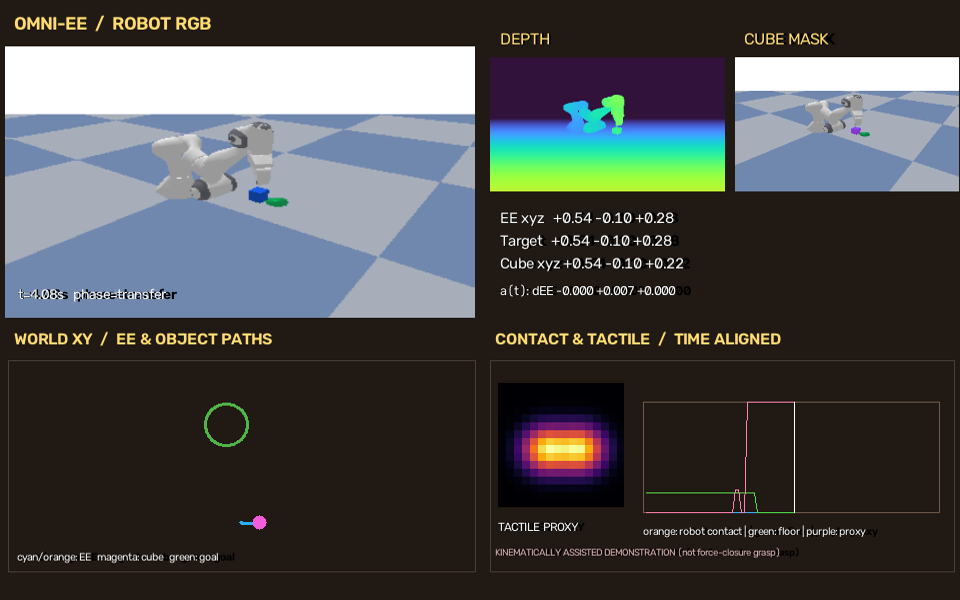

In [24]:
# 确保多媒体路径完全转换为有效的字符串，并做安全回退
safe_muxed = str(muxed) if ('muxed' in globals() and muxed is not None) else str(OUT / 'omni_dashboard.mp4')
safe_rgb = str(OUT / 'rgb_video.mp4')
safe_speech = str(speech_path) if ('speech_path' in globals() and speech_path is not None) else str(OUT / 'spoken_instruction.wav')

display(HTML('<h3>OneData-Omni-EE · Synchronized Episode</h3>'))

# 将路径作为第一个位置参数传入 Video，防止 IPython 对 None 进行 os.path.exists 检测导致 TypeError
if os.path.exists(safe_muxed):
    display(Video(safe_muxed, embed=True, html_attributes='controls playsinline'))
else:
    print("Warning: Muxed video not found at:", safe_muxed)

display(HTML('<b>Standalone RGB Video</b>'))
if os.path.exists(safe_rgb):
    display(Video(safe_rgb, embed=True))

display(HTML('<b>Spoken goal (TTS WAV)</b>'))
if os.path.exists(safe_speech):
    display(Audio(safe_speech))

# 渲染静态快照作为安全备份
if 'make_dashboard_frame' in globals():
    display(Image.fromarray(make_dashboard_frame(min(T-1, T//2))).resize((960, 600)))

## 14 · Interactive 3D playback of EE and cube trajectories (optional)

In [25]:
import plotly.graph_objects as go
fig=go.Figure()
fig.add_trace(go.Scatter3d(x=EE[:,0],y=EE[:,1],z=EE[:,2],mode='lines',name='Robot actual EE',line=dict(color='#ffa34b',width=7)))
fig.add_trace(go.Scatter3d(x=EE_TARGET[:,0],y=EE_TARGET[:,1],z=EE_TARGET[:,2],mode='lines',name='Target EE',line=dict(color='#52d8e9',width=4,dash='dash')))
fig.add_trace(go.Scatter3d(x=CUBE[:,0],y=CUBE[:,1],z=CUBE[:,2],mode='lines',name='Cube trajectory',line=dict(color='#d66fff',width=7)))
fig.add_trace(go.Scatter3d(x=[GOAL_POS[0]],y=[GOAL_POS[1]],z=[GOAL_POS[2]],mode='markers',name='Goal',marker=dict(color='#35c86c',size=9)))
fig.update_layout(title='World-aligned 3D trajectories (m)',height=520,
                  scene=dict(xaxis_title='X (m)',yaxis_title='Y (m)',zaxis_title='Z (m)',aspectmode='data'))
fig.show()
fig.write_html(str(OUT/'interactive_3d_ee.html'),include_plotlyjs=True)
print('Interactive HTML saved.')

Interactive HTML saved.


## 15 · Export the entire aligned dataset (ZIP)
Everything needed for the first synthetic sample is included. You can directly feed observations up to time `t` and the paired `action_next_*` labels to a future EE-policy training Notebook.

In [ ]:
import zipfile
README="""# OneData-Omni-EE / episode_0001

One scripted, kinematically assisted PyBullet Panda pick-and-place rollout.
Timestamps, modalities, object IDs, robot EE targets and next-frame action labels are synchronized.

Quick start:
- Inspect omni_dashboard_with_event_audio.mp4 and interactive_3d_ee.html.
- ee_robot_actions.npz has keys listed below and paired samples at the same timestamp.
- rgbd_segmentation.npz contains depth and segmentation sampled at that exact time.
- tactile_PROXY.npz contains *synthetic* gripper pad pressure maps.
- pointcloud_world.npz contains subsampled world XYZ point clouds.
- rgb/*.png, depth_mm/*.png, rgb_video.mp4 are time indexed at 12 FPS.
- spoken_instruction.wav is an episode-level spoken goal.
- event_sfx_SYNTHETIC.wav contains heuristic event cues, not physically based acoustics.
- cube_mesh_local.obj is the only standalone geometric OBJ; robot URDF uses pybullet_data.

Training:
  observation_t = modalities at timestamp[t] (plus goal speech)
  action_t = action_next_ee_delta_world_m[t], action_next_gripper_command_m[t]
  action_valid[-1] = False (no next frame).
  DO NOT include future observations, target action labels, ground-truth annotations,
  or all future pose arrays as model inputs.

CAUTION: scripted grasp attachment/IK controls, not a real force-closure policy.
A successful demonstration is not proof that any LLM can learn EE control.
"""
(OUT/'README.md').write_text(README,encoding='utf-8')

zip_path=ROOT/'OneData_Omni_EE_OneEpisode.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=5) as z:
    for f in sorted(OUT.rglob('*')):
        if f.is_file():z.write(f,f.relative_to(ROOT))
print('Ready:',zip_path)
print('ZIP size (MB):',round(zip_path.stat().st_size/1e6,2))
print('Saved episode files:',len([x for x in OUT.rglob('*') if x.is_file()]))
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Not running in Colab; ZIP remains at',zip_path)

---
### Next step (not part of this Notebook)
**Only after this single-episode data audit succeeds:** collect 10+ different robot initial states and expert traces. Train a small EE regression head / LoRA model against the **next EE target and gripper action**, with synchronized observations as input. Start with one-episode overfitting; judge success by **replaying the learned policy in the simulator**, not only by regression loss.

**Why this uses PyBullet rather than the earlier MOVi-C scenes:** MOVi-C provides rendered moving objects but **no robot / EE action labels**. Reusing its file conventions is reasonable; pretending its random object motion was a robot demonstration is not.

PyBullet robot and image API references: [official Panda example](https://github.com/bulletphysics/bullet3/blob/master/examples/pybullet/gym/pybullet_envs/examples/panda_sim.py), [URDF](https://github.com/bulletphysics/bullet3/blob/master/examples/pybullet/gym/pybullet_data/franka_panda/panda.urdf).
